<a href="https://colab.research.google.com/github/yashwand/24ai112---Yashwand-/blob/main/CAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%bash
pip install python-docx -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 1.9 MB/s eta 0:00:00


In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import matplotlib.pyplot as plt

# Reshape data for LSTM [samples, timesteps, features]
# Since we unpacked each sensor-timestep as 48 features, we can treat them as 1 timestep with 48 features
X_train_lstm = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_lstm = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define the LSTM (RNN) model
model_lstm = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mse')
model_lstm.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        28,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,041 (121.25 KB)

 Trainable params: 31,041 (121.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train the LSTM model
history = model_lstm.fit(
    X_train_lstm, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0102 - val_loss: 0.0024
Epoch 2/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0030 - val_loss: 0.0016
Epoch 3/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0025 - val_loss: 0.0021
Epoch 4/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0022 - val_loss: 0.0016
Epoch 5/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0020 - val_loss: 0.0023
Epoch 6/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0019 - val_loss: 0.0020
Epoch 7/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 8/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0017 - val_loss: 0.0025
Epoch 9/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0017 - val_loss: 0.0019
Epoch 10/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0017 - val_loss: 0.0021


In [10]:
# Evaluate the LSTM model
predictions_lstm = model_lstm.predict(X_test_lstm).flatten()

mae_lstm = mean_absolute_error(y_test, predictions_lstm)
rmse_lstm = root_mean_squared_error(y_test, predictions_lstm)

print(f"\nLSTM (RNN) Evaluation Metrics:")
print(f"Mean Absolute Error (MAE): {mae_lstm:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lstm:.4f}")

945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 878us/step

LSTM (RNN) Evaluation Metrics:
Mean Absolute Error (MAE): 0.0366
Root Mean Squared Error (RMSE): 0.0515


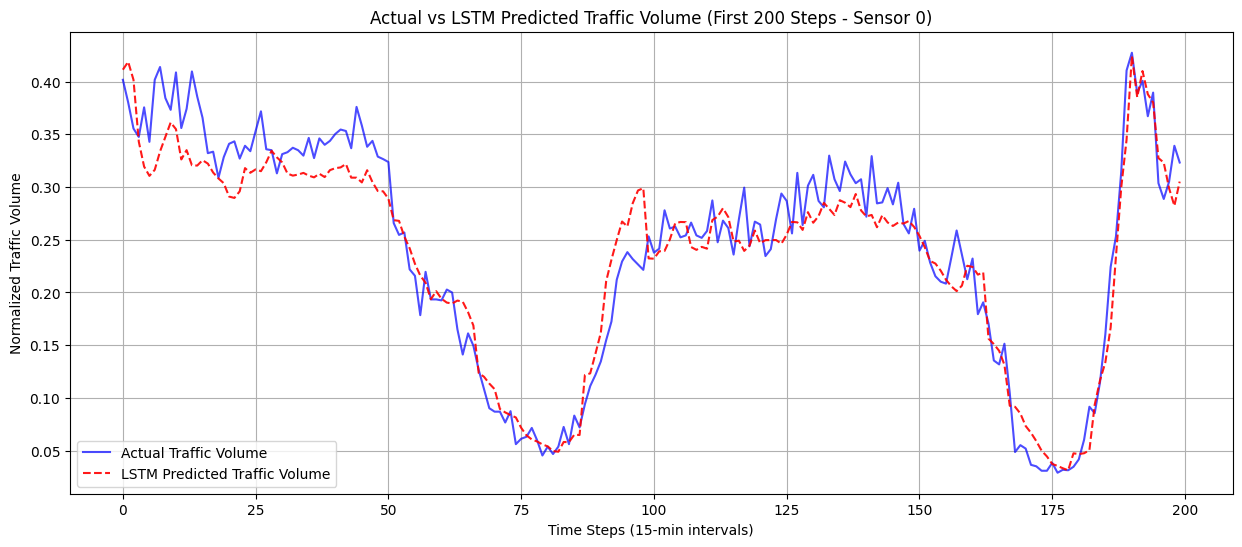

In [11]:
# Plot actual vs predicted traffic volume for LSTM (Sensor 0)
predictions_lstm_reshaped = predictions_lstm.reshape(840, 36).T

sensor_idx = 0
plt.figure(figsize=(15, 6))
plt.plot(y_test_reshaped[sensor_idx, :200], label='Actual Traffic Volume', color='blue', alpha=0.7)
plt.plot(predictions_lstm_reshaped[sensor_idx, :200], label='LSTM Predicted Traffic Volume', color='red', linestyle='--', alpha=0.9)
plt.title(f'Actual vs LSTM Predicted Traffic Volume (First 200 Steps - Sensor {sensor_idx})')
plt.xlabel('Time Steps (15-min intervals)')
plt.ylabel('Normalized Traffic Volume')
plt.legend()
plt.grid(True)
plt.show()